# Time Series - Ensembles

A `TimeSeriesEnsemble` holds **many realizations of the same series**: the same variable, at the same site, over the same time. Typical examples are model runs with perturbed inputs or parameters, or draws of a stochastic generator. Unlike a `TimeSeriesCluster`, where each series is a different site, the members of an ensemble are interchangeable: what matters is how they spread at each time step.

Covered here:

- Assembling an ensemble
- Reducers: statistics across members at each time step
- Custom reducers
- Visuals, with reducers and percentile bands highlighted over the members

```{seealso}
Check out the {doc}`Time Series - Clusters <timeseries_08_cluster>` tutorial first.
```

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.datasets import TemperatureSeries, TimeSeriesEnsemble

# This avoids warnings related to uninstalled fonts
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

rng = np.random.default_rng(seed=5)  # ensure reproducibility

## Build a synthetic ensemble

Fifty members of daily temperature over one year. Each member shares the seasonal cycle, but has its own bias and its own weather (an autoregressive anomaly), like runs of a model with uncertain inputs. Members are assembled in memory with `.set_data()` and `.append()`:

In [2]:
n_members = 50
n = 365
t = np.arange(n)
dates = pd.date_range(start="2021-01-01", periods=n, freq="D")
seasonal = 18 + 5 * np.sin(2 * np.pi * (t - 100) / 365)

def make_anomaly(phi, sd):
    # autoregressive anomaly: a[t] = phi * a[t-1] + noise
    a = np.zeros(n)
    e = rng.normal(loc=0, scale=sd, size=n)
    for i in range(1, n):
        a[i] = phi * a[i - 1] + e[i]
    return a

tse = TimeSeriesEnsemble(name="Projections", base_object=TemperatureSeries)
for k in range(n_members):
    bias = rng.normal(loc=0, scale=0.8)
    values = seasonal + bias + make_anomaly(phi=0.85, sd=1.2)
    name = f"R{k + 1:02d}"
    ts = TemperatureSeries(name=name, alias=name)
    ts.set_data(
        input_df=pd.DataFrame({"datetime": dates, "T": values}),
        input_dtfield="datetime",
        input_varfield="T",
    )
    tse.append(new_object=ts)

tse.update(details=True)
print(f"Members: {len(tse.catalog)}")

Members: 50


## Reducers

Reducers compute a statistic across all members at each time step, returning a `pandas.DataFrame` with the datetime and one column per statistic, named `{varalias}_{statistic}`. The ensemble mean:

In [3]:
tse.mean().head()

,datetime,TAS_mean
0,2021-01-01,12.980556
1,2021-01-02,13.090094
2,2021-01-03,13.339110
3,2021-01-04,13.175806
4,2021-01-05,13.262177


Other shortcuts follow the same pattern: `.median()`, `.min()`, `.max()`, `.std()` and `.rng()` (range, max minus min). For instance, the spread of the members at each time step:

In [4]:
df = pd.merge(left=tse.std(), right=tse.rng(), on="datetime")
df.describe().round(2)

,datetime,TAS_std,TAS_rng
count,365,365.00,365.00
mean,2021-07-02 00:00:00,2.38,10.70
min,2021-01-01 00:00:00,0.83,3.69
25%,2021-04-02 00:00:00,2.22,9.64
50%,2021-07-02 00:00:00,2.37,10.53
75%,2021-10-01 00:00:00,2.53,11.69
max,2021-12-31 00:00:00,3.05,15.11
std,NaN,0.25,1.62


Percentiles are named by their value, zero padded for single digits:

In [5]:
tse.percentiles(values=[5, 50, 95]).head()

,datetime,TAS_p05,TAS_p50,TAS_p95
0,2021-01-01,11.693718,13.015260,14.442660
1,2021-01-02,10.666103,13.132855,15.363180
2,2021-01-03,10.850595,13.187258,16.303278
3,2021-01-04,10.204379,13.073605,16.965536
4,2021-01-05,9.807915,13.233080,16.525497


Use `.stats()` for a combined table, with `basic=True` to keep only the quartiles:

In [6]:
tse.stats(basic=True).head()

,datetime,TAS_sum,TAS_mean,TAS_std,TAS_min,TAS_max,TAS_p25,TAS_p50,TAS_p75
0,2021-01-01,649.027782,12.980556,0.831914,11.021421,14.712603,12.383723,13.015260,13.448634
1,2021-01-02,654.504715,13.090094,1.397770,9.769784,15.754714,12.176977,13.132855,13.946630
2,2021-01-03,666.955508,13.339110,1.658178,9.517009,16.505162,12.006084,13.187258,14.604220
3,2021-01-04,658.790304,13.175806,2.063791,9.095344,17.591517,11.706462,13.073605,14.393864
4,2021-01-05,663.108836,13.262177,2.024634,9.098102,17.900176,11.761767,13.233080,14.552708


```{note}
Reducers ignore missing values, so members with gaps or shorter records still contribute where they have data.
```

### Custom reducers

The `.reducer()` method takes any function that reduces along an axis. Each entry maps an output name to a function (`Func`) and an optional extra argument (`Args`). For instance, the fraction of members above 25 C at each time step reads as the probability of a hot day. The five most likely hot days:

In [7]:
def fraction_above_25(x, axis):
    return np.nanmean(x > 25, axis=axis)

df_hot = tse.reducer(
    reducer_funcs={"hot": {"Func": fraction_above_25, "Args": None}}
)
df_hot.nlargest(5, "TAS_hot")

,datetime,TAS_hot
177,2021-06-27,0.26
195,2021-07-15,0.26
210,2021-07-30,0.26
214,2021-08-03,0.26
216,2021-08-05,0.26


### Reducers as series

To use a reducer as a regular series, get it with `.get_reducer_series()`. It returns an object of the ensemble base type (here a `TemperatureSeries`), so all its methods are available:

<class 'plans.datasets.chrono.TemperatureSeries'>


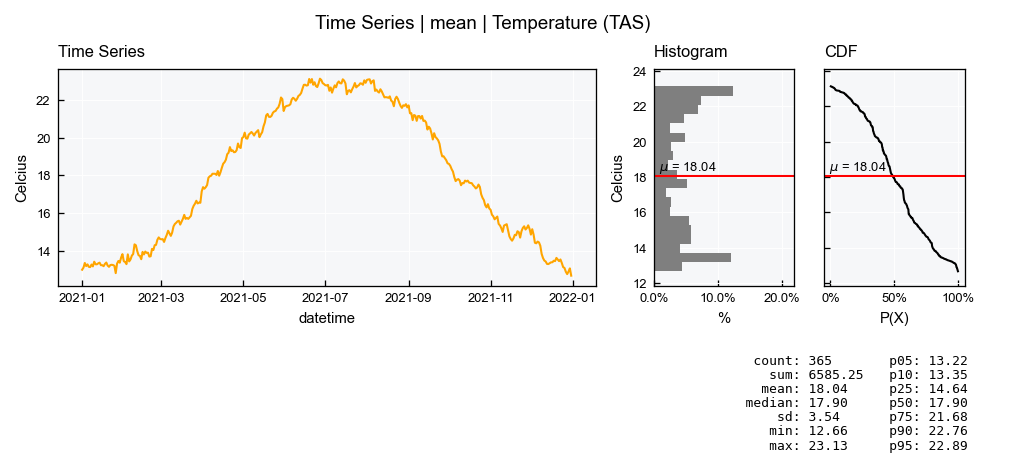

In [8]:
ts_mean = tse.get_reducer_series(name="mean")
print(type(ts_mean))
ts_mean.view()

## Visualizations

The default view of an ensemble draws the members in a light background style, and highlights on top the reducers listed in `view_specs["reducers"]` (the mean, by default) and the percentile bands in `view_specs["bands"]` (5 to 95, by default):

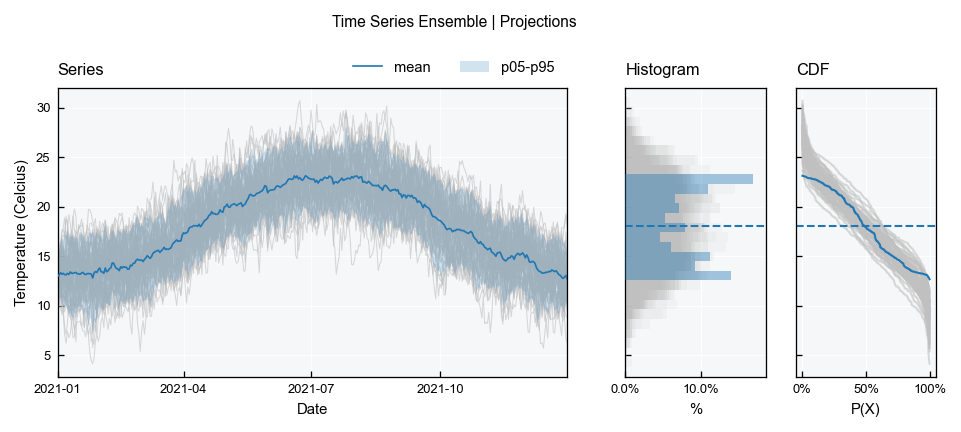

In [9]:
tse.view()

Note how narrow the histogram and the CDF of the mean are, compared to any member. Averaging cancels out the weather of individual members, so the ensemble mean is a summary of the ensemble, not a realistic realization: it has far fewer warm and cold extremes than any member.

### Choosing reducers and bands

Reducers are given by name: `mean`, `median`, `min`, `max` or a percentile such as `p90`. Bands are given as `[low, high]` percentile pairs, and nest when more than one is given:

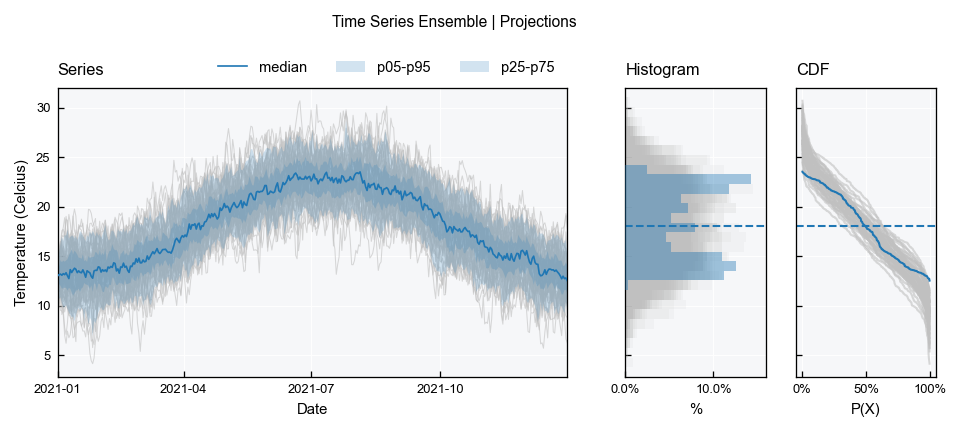

In [10]:
tse.view_specs["reducers"] = ["median"]
tse.view_specs["bands"] = [[5, 95], [25, 75]]
tse.view()

### Highlighting members

Like in a cluster, `view_specs["highlight"]` draws selected members in color. Compare a single member against the mean: the member is as variable as the background, while the mean is smooth:

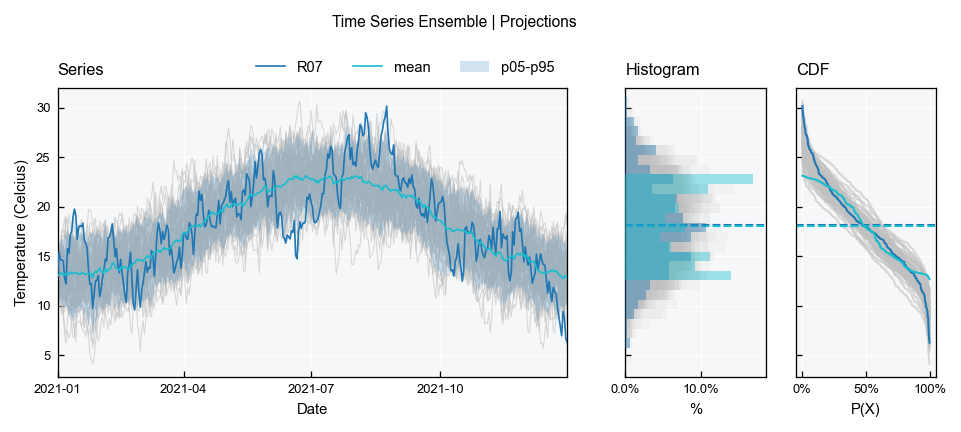

In [11]:
tse.view_specs["reducers"] = ["mean"]
tse.view_specs["bands"] = [[5, 95]]
tse.view_specs["highlight"] = ["R07"]
tse.view()

For the series panel only, use the `series-simple` layout:

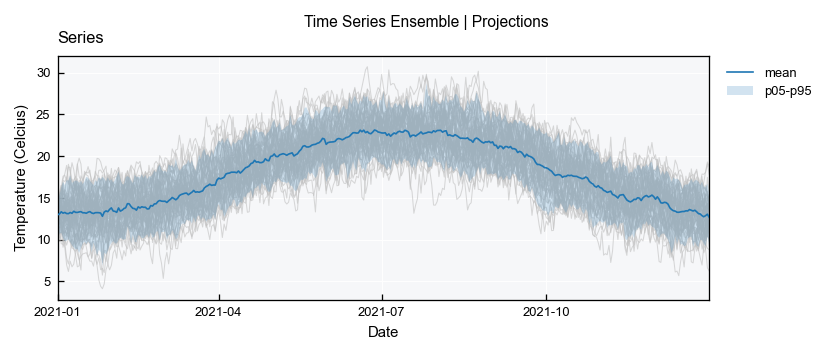

In [12]:
tse.view_specs["highlight"] = None
tse.view_specs["layout"] = "series-simple"
tse.view()

## Recap

- A `TimeSeriesEnsemble` holds realizations of the same series, assembled like any collection.
- Reducers (`.mean()`, `.percentiles()`, `.stats()`, ...) compute statistics across members at each time step, ignoring missing values; `.reducer()` takes custom functions.
- `.get_reducer_series()` turns a reducer into a regular series.
- The default view highlights reducers and percentile bands over the members, set by `view_specs["reducers"]` and `view_specs["bands"]`.